2013-07-30 11:40:00+00:00    846.721258
2013-07-30 11:41:00+00:00    846.655632
2013-07-30 11:42:00+00:00    846.575595
2013-07-30 11:43:00+00:00    846.481149
2013-07-30 11:44:00+00:00    846.372295
                                ...    
2013-07-30 13:16:00+00:00    775.905288
2013-07-30 13:17:00+00:00    774.505207
2013-07-30 13:18:00+00:00    773.092197
2013-07-30 13:19:00+00:00    771.666288
2013-07-30 13:20:00+00:00    770.227510
Freq: T, Name: ghi, Length: 101, dtype: float64
2013-07-30 11:40:00+00:00    772.726278
2013-07-30 11:41:00+00:00    772.708795
2013-07-30 11:42:00+00:00    772.687471
2013-07-30 11:43:00+00:00    772.662304
2013-07-30 11:44:00+00:00    772.633292
                                ...    
2013-07-30 13:16:00+00:00    752.681819
2013-07-30 13:17:00+00:00    752.260212
2013-07-30 13:18:00+00:00    751.833651
2013-07-30 13:19:00+00:00    751.402112
2013-07-30 13:20:00+00:00    750.965571
Freq: T, Name: dni, Length: 101, dtype: float64
2013-07-30 11:40:00+00:0

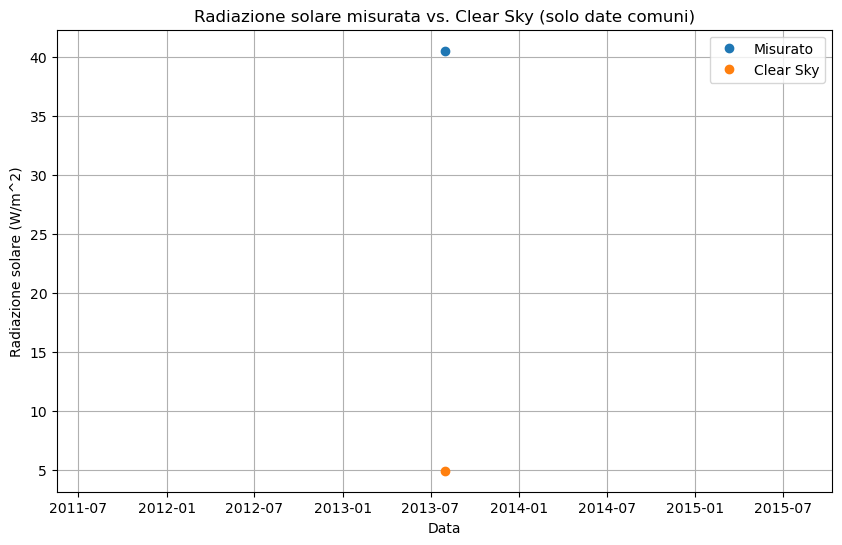

ValueError: x and y must have length at least 2.

In [3]:
import pandas as pd
from datetime import datetime
import sqlite3
import pvlib
from pvlib import clearsky, atmosphere, solarposition
from pvlib.location import Location
from pvlib.iotools import read_tmy3
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# Connetti al database SQLite
conn = sqlite3.connect(r'C:\Users\vitto\Desktop\VB\UNIVERSITÀ\STAGE\RADIAZIONE\nuvole.db')

# Carica i dati misurati dalla tabella
query = "SELECT data,modello, stazione FROM st83clearsky WHERE modello IS NOT NULL AND modello != 'NULL' AND stazione IS NOT NULL AND stazione != 'NULL'"
data_misurati = pd.read_sql_query(query, conn)

# Chiudi la connessione al database
conn.close()

# Lavoro con i dati del database SQL
data_misurati['data'] = pd.to_datetime(data_misurati['data'])
data_misurati = data_misurati.set_index('data')
data_misurati = data_misurati.resample('1T').asfreq()

# Converti l'indice a timezone-aware
data_misurati.index = data_misurati.index.tz_localize('GMT')

# Definisci la posizione (latitudine e longitudine)
latitude = 45.07
longitude = 7.59
location = pvlib.location.Location(latitude, longitude)

# Calcola i valori Clear Sky
cs = location.get_clearsky(pd.date_range(data_misurati.index[700], data_misurati.index[800], freq='1T', tz='GMT'))
print(cs['ghi'])
print(cs['dni'])
print(cs['dhi'])
# Somma i dati giornalieri per la radiazione totale
somma_giornaliera_clearsky = (cs.resample('D').sum())*0.00006

# Unisci i dati misurati con i valori Clear Sky
merged_data = pd.merge(data_misurati, somma_giornaliera_clearsky, left_index=True, right_index=True)
print(merged_data.columns)

# Filtra le date comuni tra 'stazione' e 'dni'
common_dates = merged_data.dropna(subset=['stazione', 'ghi']).index

# Filtra i dati di 'stazione' e 'dni' per le date comuni
stazione_common = merged_data.loc[common_dates, 'stazione']
dni_common = merged_data.loc[common_dates, 'ghi']

# Plot dei dati con punti solo per le date comuni
plt.figure(figsize=(10, 6))

# Dati misurati (stazione)
plt.plot(common_dates, stazione_common, label='Misurato', marker='o', linestyle='None')

# Dati Clear Sky (dni)
plt.plot(common_dates, dni_common, label='Clear Sky', marker='o', linestyle='None')

plt.xlabel('Data')
plt.ylabel('Radiazione solare (W/m^2)')
plt.title('Radiazione solare misurata vs. Clear Sky (solo date comuni)')
plt.legend()
plt.grid(True)
plt.show()



# Converti i dati in array di numpy
x = np.array(dni_common)
y = np.array(stazione_common)

# Calcola la pendenza (slope) e l'intercetta (intercept) della regressione lineare
A = np.vstack([x, np.ones_like(x)]).T
slope, intercept = np.linalg.lstsq(A, y, rcond=None)[0]

# Calcola i valori della linea di regressione
regression_line = slope * x + intercept

# Calcola il coefficiente di correlazione di Pearson
correlation_coefficient, p_value = pearsonr(x, y)

# Crea il grafico di dispersione con la linea di regressione

plt.figure(figsize=(10, 6))
plt.scatter(x, y, label=f'Correlazione: {correlation_coefficient:.2f}', alpha=0.5)
plt.plot(x, regression_line, color='red', label=f'Regressione lineare\ny = {slope:.2f}x + {intercept:.2f}')
plt.xlabel('modello')
plt.ylabel('stazione')
# Aggiungi testo per pendenza e R^2
plt.text(0.05, 0.95, f'Pendence: {slope:.2f}', transform=plt.gca().transAxes, fontsize=12, verticalalignment='top')
plt.text(0.05, 0.90, f'$R^2$: {correlation_coefficient:.2f}', transform=plt.gca().transAxes, fontsize=12, verticalalignment='top')